In [1]:
# 1. IMPORT LIBRARIES
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Preprocessing & Selection
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif

# Sklearn Model & Metrics
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, 
    classification_report, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

# Set styling for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)



In [2]:
# 2. LOAD DATASET

file_name = "weather_classification_data.csv"

if os.path.exists(file_name):
    df = pd.read_csv(file_name)
    print(f"Dataset loaded successfully! Shape: {df.shape}")
else:
    raise FileNotFoundError(f"Could not find the file: {file_name}")

Dataset loaded successfully! Shape: (13200, 11)


In [3]:
# 3. DATA UNDERSTANDING

print(df.info())

print(df.head())

print(df.describe().T)

print(df['Weather Type'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Temperature           13200 non-null  float64
 1   Humidity              13200 non-null  int64  
 2   Wind Speed            13200 non-null  float64
 3   Precipitation (%)     13200 non-null  float64
 4   Cloud Cover           13200 non-null  object 
 5   Atmospheric Pressure  13200 non-null  float64
 6   UV Index              13200 non-null  int64  
 7   Season                13200 non-null  object 
 8   Visibility (km)       13200 non-null  float64
 9   Location              13200 non-null  object 
 10  Weather Type          13200 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 1.1+ MB
None
   Temperature  Humidity  Wind Speed  Precipitation (%)    Cloud Cover  \
0         14.0        73         9.5               82.0  partly cloudy   
1         39.

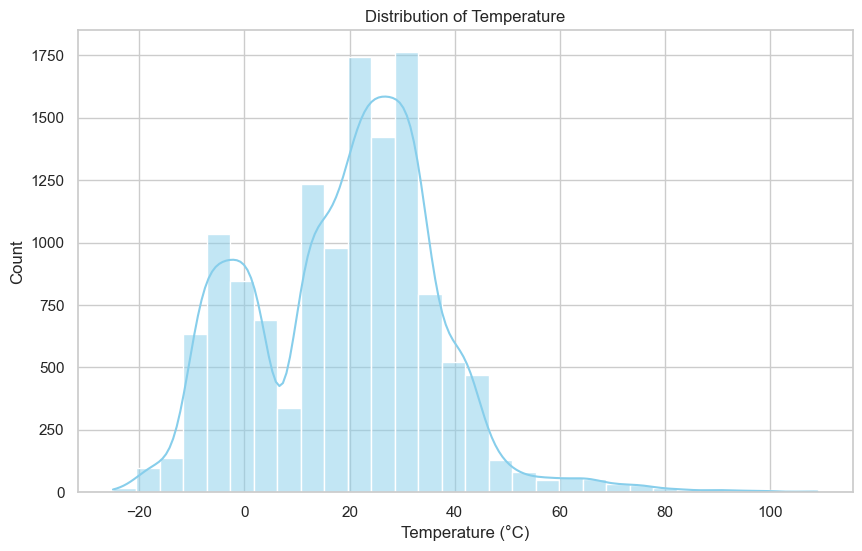

In [4]:
# 4. EXPLORATORY DATA ANALYSIS (EDA)

# For demonstration purposes, plots are generated and shown. 
# In a local environment, plt.show() will pop open windows or render inline.

# 4.1 Histogram (Temperature Distribution)
plt.figure()
sns.histplot(df['Temperature'], kde=True, bins=30, color='skyblue')
plt.title('Distribution of Temperature')
plt.xlabel('Temperature (°C)')
plt.show()

In [6]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

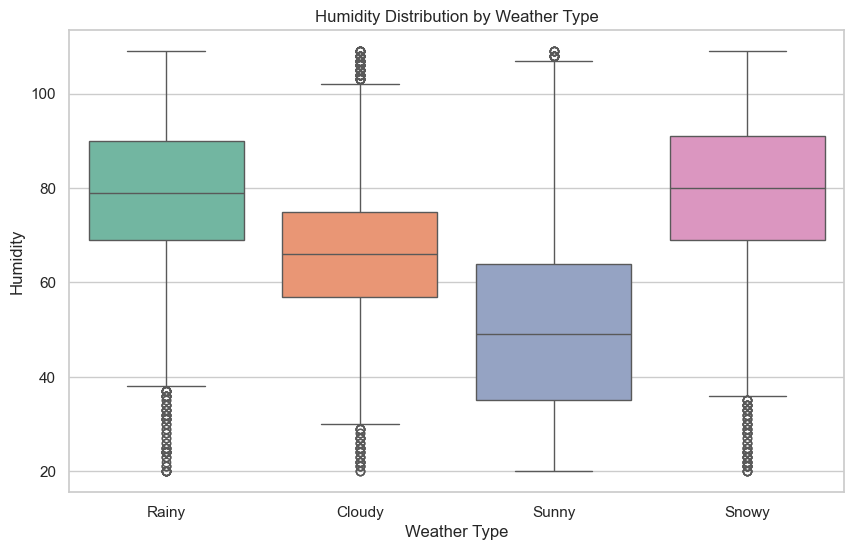

In [7]:
# 4.2 Boxplot (Humidity across Weather Types)
plt.figure()
sns.boxplot(x='Weather Type', y='Humidity', data=df, palette='Set2')
plt.title('Humidity Distribution by Weather Type')
plt.show()

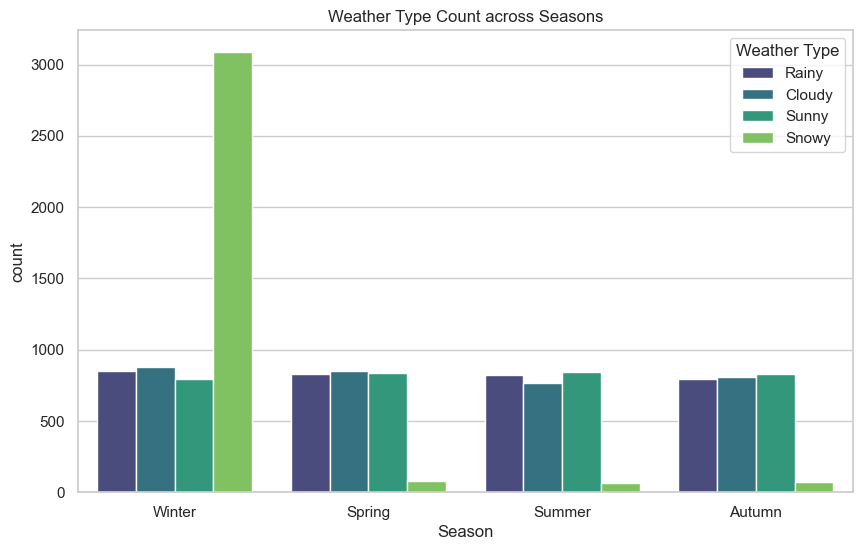

In [8]:
# 4.3 Countplot (Season Distribution)
plt.figure()
sns.countplot(x='Season', hue='Weather Type', data=df, palette='viridis')
plt.title('Weather Type Count across Seasons')
plt.show()


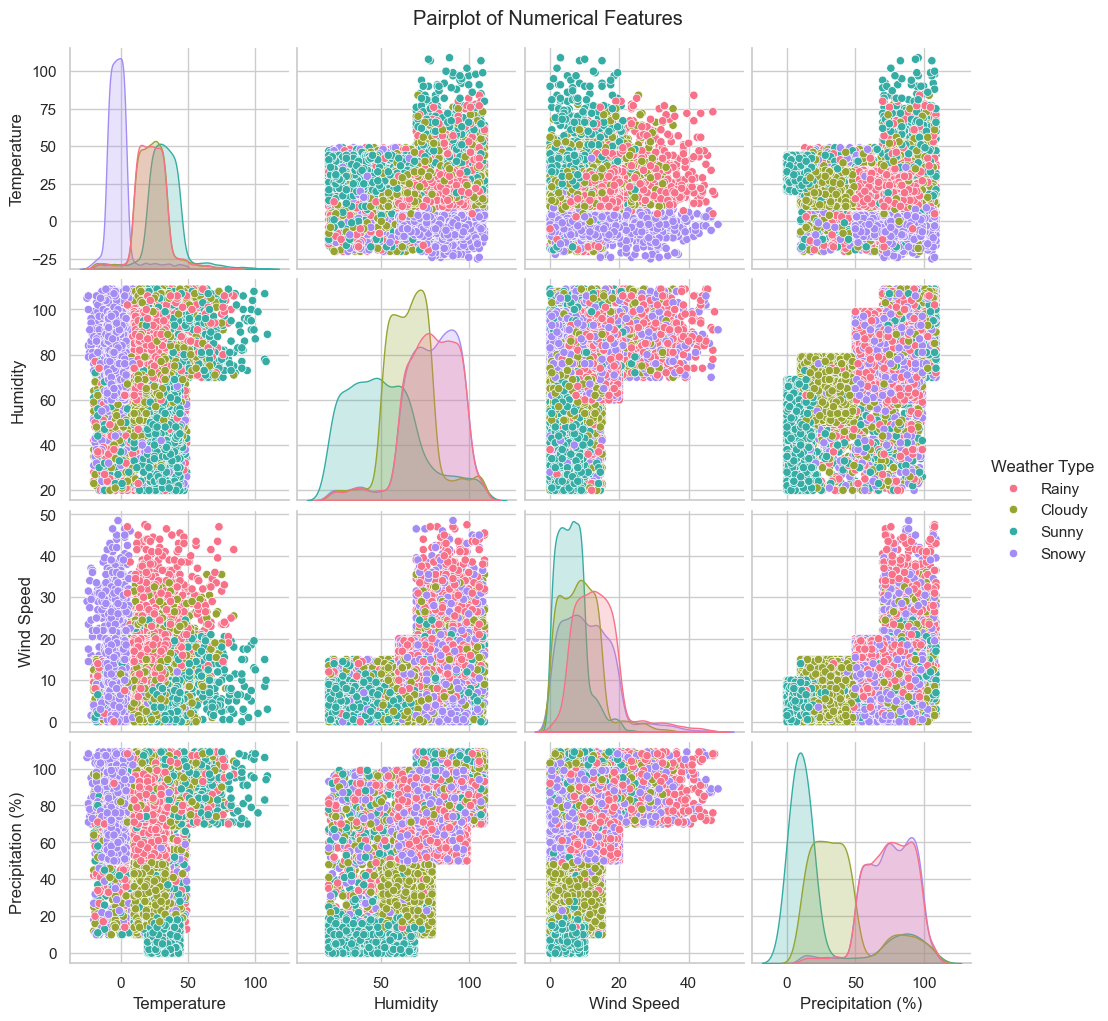

In [9]:
# 4.4 Pairplot (Subset of features to avoid performance lag)
numerical_cols = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)']
sns.pairplot(df[numerical_cols + ['Weather Type']], hue='Weather Type', palette='husl')
plt.suptitle('Pairplot of Numerical Features', y=1.02)
plt.show()

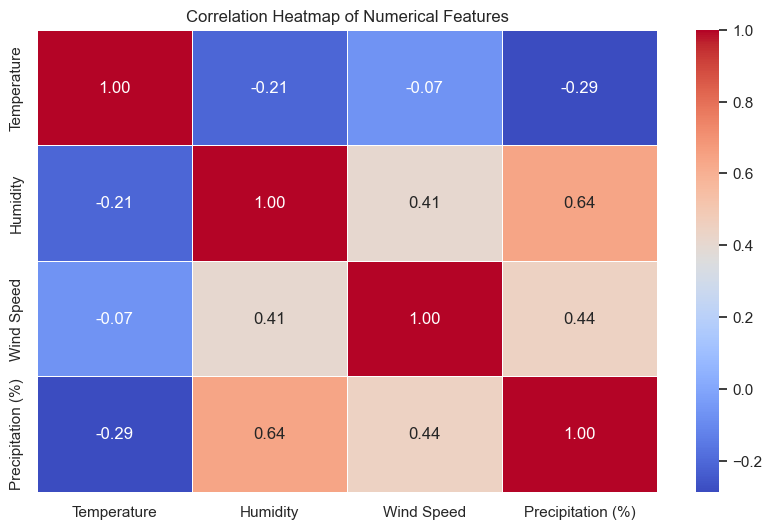

In [11]:
#4.5 Heatmap (Correlation of Numerical Features)

plt.figure()
corr_matrix = df[numerical_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

In [12]:
# 5. DATA CLEANING

print(df.isnull().sum())

# Handle missing values if any (Simple Imputation)
# Note: From df.info(), this dataset is already clean, but we include it as standard practice.

for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype == 'object':
            df[col].fillna(df[col].mode()[0], inplace=True)
        else:
            df[col].fillna(df[col].median(), inplace=True)

# Drop duplicates if any
duplicate_count = df.duplicated().sum()
if duplicate_count > 0:
    print(f"Removing {duplicate_count} duplicate rows.")
    df.drop_duplicates(inplace=True)


Temperature             0
Humidity                0
Wind Speed              0
Precipitation (%)       0
Cloud Cover             0
Atmospheric Pressure    0
UV Index                0
Season                  0
Visibility (km)         0
Location                0
Weather Type            0
dtype: int64


In [13]:
# 6. FEATURE ENGINEERING

# Creating a dummy engineered feature: 'Apparent Comfort Index' 
# (Simplistic interaction term of Temperature and Humidity)

df['Comfort_Index'] = df['Temperature'] * (1 - (df['Humidity'] / 100))
print("\nFeature Engineering Completed. Created 'Comfort_Index'.")


Feature Engineering Completed. Created 'Comfort_Index'.


In [14]:
# 7. ENCODING

# Split Features (X) and Target (y)

X = df.drop(columns=['Weather Type'])
y = df['Weather Type']

# Identify categorical features in X

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
print(f"Categorical features to encode: {categorical_cols}")

# One-Hot Encoding for independent categorical variables

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# Label Encoding for the target variable (Weather Type)

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


Categorical features to encode: ['Cloud Cover', 'Season', 'Location']


In [15]:
# 8. FEATURE SELECTION

# Using SelectKBest to select top features based on ANOVA F-value

# Let's dynamically select top 8 features

selector = SelectKBest(score_func=f_classif, k=8)
X_selected = selector.fit_transform(X, y_encoded)

# Keep track of selected column names

selected_indices = selector.get_support(indices=True)
selected_features = X.columns[selected_indices].tolist()
print(f"\nSelected Top Features: {selected_features}")

X_final = pd.DataFrame(X_selected, columns=selected_features)



Selected Top Features: ['Temperature', 'Humidity', 'Precipitation (%)', 'UV Index', 'Visibility (km)', 'Comfort_Index', 'Cloud Cover_overcast', 'Season_Winter']


In [16]:
# 9. FEATURE SCALING

# SVMs are highly sensitive to unscaled feature ranges. 

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_final)

In [17]:
# 10. STRATIFIED TRAIN-TEST SPLIT

# Using stratify=y_encoded ensures target proportions are identical in train and test sets.

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)
print(f"\nTrain size: {X_train.shape[0]}, Test size: {X_test.shape[0]}")


Train size: 10560, Test size: 2640


In [18]:
# 11. SVM MODEL & CROSS VALIDATION

# Initialize baseline SVM

svm_baseline = SVC(kernel='rbf', random_state=42)

# Performing a Stratified 5-Fold Cross Validation on training data

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(svm_baseline, X_train, y_train, cv=cv, scoring='accuracy')

print(f"\nBaseline SVM Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


Baseline SVM Cross-Validation Accuracy: 0.8943 (+/- 0.0044)


In [19]:
# 12. HYPERPARAMETER TUNING (GridSearchCV)

# Defining parameter grid (scaled down to avoid heavy execution delays)

param_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto'],
    'kernel': ['rbf']
}

print("\nRunning GridSearchCV (this may take a moment)...")
grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=cv, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

print(f"Best Parameters: {grid_search.best_params_}")
best_svm_model = grid_search.best_estimator_


Running GridSearchCV (this may take a moment)...
Best Parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}


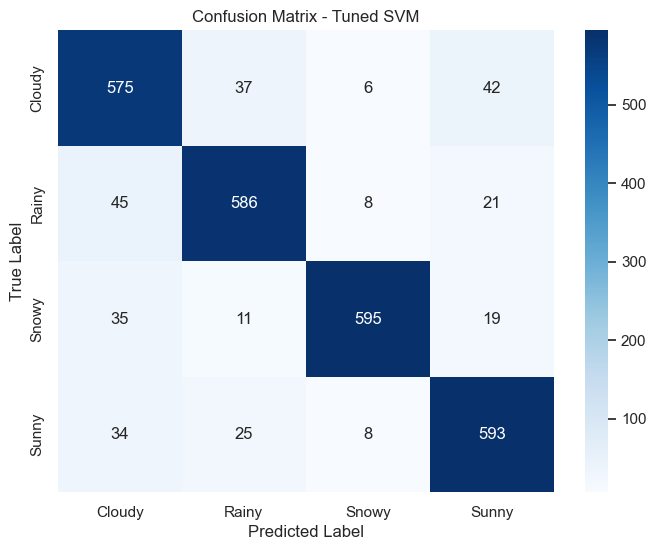


--- Classification Report ---
              precision    recall  f1-score   support

      Cloudy       0.83      0.87      0.85       660
       Rainy       0.89      0.89      0.89       660
       Snowy       0.96      0.90      0.93       660
       Sunny       0.88      0.90      0.89       660

    accuracy                           0.89      2640
   macro avg       0.89      0.89      0.89      2640
weighted avg       0.89      0.89      0.89      2640

Accuracy : 0.8898
Precision: 0.8917
Recall   : 0.8898
F1-Score : 0.8903


In [20]:
# 13. MODEL EVALUATION

# Predict on the test set using the best model

y_pred = best_svm_model.predict(X_test)

# --- Confusion Matrix ---

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=label_encoder.classes_, 
            yticklabels=label_encoder.classes_)
plt.title('Confusion Matrix - Tuned SVM')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# --- Classification Report ---

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# --- Specific Metrics ---

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

In [21]:
# 14. SAVE MODEL (joblib)

model_filename = "best_svm_weather_model.pkl"
scaler_filename = "scaler.pkl"
encoder_filename = "label_encoder.pkl"

joblib.dump(best_svm_model, model_filename)
joblib.dump(scaler, scaler_filename)
joblib.dump(label_encoder, encoder_filename)

print(f"\nSaved model, scaler, and encoder successfully configurations.")


Saved model, scaler, and encoder successfully configurations.


In [22]:
# 15. PREDICT ON NEW DATA

# Creating a dummy new raw instance mimicking original input features

# (Must have original columns before preprocessing)

new_data_raw = pd.DataFrame([{
    'Temperature': 25.5,
    'Humidity': 65,
    'Wind Speed': 12.0,
    'Precipitation (%)': 45.0,
    'Cloud Cover': 'partly cloudy',
    'Atmospheric Pressure': 1012.5,
    'UV Index': 5,
    'Season': 'Summer',
    'Visibility (km)': 8.0,
    'Location': 'inland'
}])

In [23]:
# Pipeline simulation for new incoming inference data:
# 1. Feature Engineering

new_data_raw['Comfort_Index'] = new_data_raw['Temperature'] * (1 - (new_data_raw['Humidity'] / 100))

# 2. Re-create dummy columns with matching schema from original training feature matrix X

new_data_encoded = pd.get_dummies(new_data_raw, columns=categorical_cols)
new_data_encoded = new_data_encoded.reindex(columns=X.columns, fill_value=0)

# 3. Apply Feature Selection filtering

new_data_selected = new_data_encoded[selected_features]

# 4. Scale

new_data_scaled = scaler.transform(new_data_selected)

# 5. Predict

new_pred_encoded = best_svm_model.predict(new_data_scaled)
new_pred_label = label_encoder.inverse_transform(new_pred_encoded)

print(f"\n--- Prediction on New Sample Data ---")
print(f"Input Features: \n{new_data_raw.iloc[0].to_dict()}")
print(f"Predicted Weather Class: **{new_pred_label[0]}**")


--- Prediction on New Sample Data ---
Input Features: 
{'Temperature': 25.5, 'Humidity': 65, 'Wind Speed': 12.0, 'Precipitation (%)': 45.0, 'Cloud Cover': 'partly cloudy', 'Atmospheric Pressure': 1012.5, 'UV Index': 5, 'Season': 'Summer', 'Visibility (km)': 8.0, 'Location': 'inland', 'Comfort_Index': 8.924999999999999}
Predicted Weather Class: **Cloudy**
